<a href="https://colab.research.google.com/github/luisrogelioaguilar1-cell/everpeak_analysis/blob/main/notebooks/everpeak_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EverPeak Retail | Análisis exploratorio, calidad de datos y segmentación

**Proyecto de portafolio — TripleTen | Python, pandas, matplotlib, seaborn**

## Objetivo
Explorar las transacciones de EverPeak, evaluar calidad de datos, identificar valores atípicos, justificar su tratamiento y crear segmentos de volumen y método de pago para apoyar decisiones de negocio.

**Nota:** Este notebook reúne ejercicios realizados durante el aprendizaje. Los resultados y las conclusiones definitivas deben completarse **después de ejecutarlo con los archivos reales**. No se inventan métricas. Los CSV de TripleTen solo deben publicarse si sus condiciones de uso lo permiten.

## 0. Cómo usar este notebook en Google Colab

1. Abre [Google Colab](https://colab.research.google.com/), selecciona **Archivo → Subir notebook** y elige este `.ipynb`.
2. Descarga desde TripleTen `everpeak_clean.csv` y, si lo tienes, `everpeak_retail.csv` a tu computadora.
3. Ejecuta la siguiente celda y selecciona los archivos CSV en el cuadro de carga.
4. Ejecuta las celdas en orden (**Entorno de ejecución → Ejecutar todas**).
5. Revisa los gráficos, escribe tus hallazgos en las secciones de interpretación y guarda una copia en Drive.

El archivo `everpeak_retail.csv` es opcional; la segmentación por método de pago se ejecutará únicamente si está disponible.

In [6]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de gráficos
sns.set_theme(style="whitegrid")

# Carpeta de Google Drive
data_dir = Path("/content/drive/MyDrive/EverPeak_Data")

# Rutas de los archivos
clean_path = data_dir / "everpeak_clean.csv"
retail_path = data_dir / "everpeak_retail.csv"

# Verificar que existan los archivos
if not clean_path.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {clean_path}"
    )

if not retail_path.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {retail_path}"
    )

# Cargar los datasets
df = pd.read_csv(clean_path)
df_retail = pd.read_csv(retail_path)

# Confirmar que se cargaron correctamente
print("Archivos cargados correctamente desde Google Drive.")
print("Dataset limpio:", df.shape)
print("Dataset original:", df_retail.shape)

# Mostrar los primeros registros
display(df.head())


Archivos cargados correctamente desde Google Drive.
Dataset limpio: (5000, 14)
Dataset original: (5008, 11)


,order_id,order_date,customer_id,product_category,price,quantity,order_value,payment_method,city,state,customer_age,quantity_invalid_flag,age_invalid_flag,state_missing_flag
0,1,2024-02-02,2616,Sports,269,50,13385,credit_card,New York,NY,66,0,0,0
1,2,2024-10-10,1736,Grocery,66,10,660,debit_card,Los Angeles,CA,24,1,0,0
2,3,2024-08-27,2543,Sports,267,19,5073,credit_card,Chicago,IL,23,1,0,0
3,4,2024-06-09,2252,Toys,114,125,14290,credit_card,New York,NY,70,0,0,0
4,5,2024-06-07,1583,Fashion,729,16,11754,credit_card,Houston,TX,75,0,0,0


## 1. Visión general y calidad de los datos
Revisamos columnas, tipos, faltantes y duplicados. Las variables de interés son `price`, `quantity`, `order_value` y `customer_age`. Los identificadores no se interpretan como magnitudes de negocio.

In [3]:
df.info()
display(df.head())
print("Filas y columnas:", df.shape)
print("Duplicados exactos:", df.duplicated().sum())
display(df.isna().sum().rename("valores_nulos").to_frame())

num_cols = [c for c in ["price", "quantity", "order_value", "customer_age"] if c in df.columns]
print("Columnas numéricas relevantes disponibles:", num_cols)
if not num_cols:
    raise ValueError("No se encontraron las columnas numéricas esperadas.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   order_id               5000 non-null   int64 
 1   order_date             5000 non-null   object
 2   customer_id            5000 non-null   int64 
 3   product_category       5000 non-null   object
 4   price                  5000 non-null   int64 
 5   quantity               5000 non-null   int64 
 6   order_value            5000 non-null   int64 
 7   payment_method         5000 non-null   object
 8   city                   5000 non-null   object
 9   state                  5000 non-null   object
 10  customer_age           5000 non-null   int64 
 11  quantity_invalid_flag  5000 non-null   int64 
 12  age_invalid_flag       5000 non-null   int64 
 13  state_missing_flag     5000 non-null   int64 
dtypes: int64(9), object(5)
memory usage: 547.0+ KB


,order_id,order_date,customer_id,product_category,price,quantity,order_value,payment_method,city,state,customer_age,quantity_invalid_flag,age_invalid_flag,state_missing_flag
0,1,2024-02-02,2616,Sports,269,50,13385,credit_card,New York,NY,66,0,0,0
1,2,2024-10-10,1736,Grocery,66,10,660,debit_card,Los Angeles,CA,24,1,0,0
2,3,2024-08-27,2543,Sports,267,19,5073,credit_card,Chicago,IL,23,1,0,0
3,4,2024-06-09,2252,Toys,114,125,14290,credit_card,New York,NY,70,0,0,0
4,5,2024-06-07,1583,Fashion,729,16,11754,credit_card,Houston,TX,75,0,0,0


Filas y columnas: (5000, 14)
Duplicados exactos: 0


,valores_nulos
order_id,0
order_date,0
customer_id,0
product_category,0
price,0
quantity,0
order_value,0
payment_method,0
city,0
state,0


Columnas numéricas relevantes disponibles: ['price', 'quantity', 'order_value', 'customer_age']


In [4]:
# Análisis de valores faltantes por columna
missingness = pd.DataFrame({
    "valores_faltantes": df.isna().sum(),
    "porcentaje_faltante": (df.isna().mean() * 100).round(2)
})

missingness = missingness.sort_values(
    by="porcentaje_faltante",
    ascending=False
)

display(missingness)


,valores_faltantes,porcentaje_faltante
order_id,0,0.0
order_date,0,0.0
customer_id,0,0.0
product_category,0,0.0
price,0,0.0
quantity,0,0.0
order_value,0,0.0
payment_method,0,0.0
city,0,0.0
state,0,0.0


## 2. Estadísticas descriptivas
Comparamos media, mediana, desviación estándar, cuartiles y extremos para explorar posibles asimetrías.

In [5]:
display(df[num_cols].describe().T)
resumen_central = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "diferencia_media_mediana": df[num_cols].mean() - df[num_cols].median()
})
display(resumen_central)

,count,mean,std,min,25%,50%,75%,max
price,5000.0,756.3874,1173.265182,12.0,218.0,457.0,847.25,36708.0
quantity,5000.0,32.3598,93.403826,1.0,7.0,14.0,23.00,2083.0
order_value,5000.0,10075.5238,12406.603152,12.0,3094.0,10341.0,13160.50,303824.0
customer_age,5000.0,49.1208,17.710679,18.0,34.0,49.0,64.00,80.0


,media,mediana,diferencia_media_mediana
price,756.3874,457.0,299.3874
quantity,32.3598,14.0,18.3598
order_value,10075.5238,10341.0,-265.4762
customer_age,49.1208,49.0,0.1208


## 3. Visualización diagnóstica
Los histogramas muestran la forma de la distribución y los boxplots permiten detectar posibles extremos.

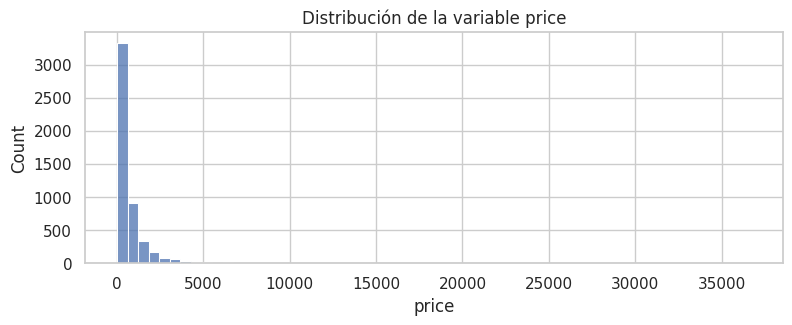

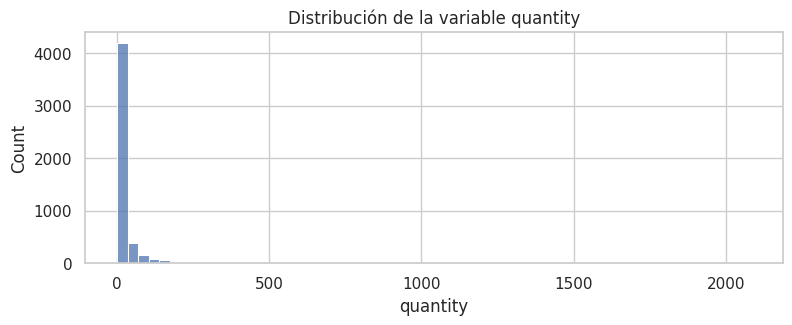

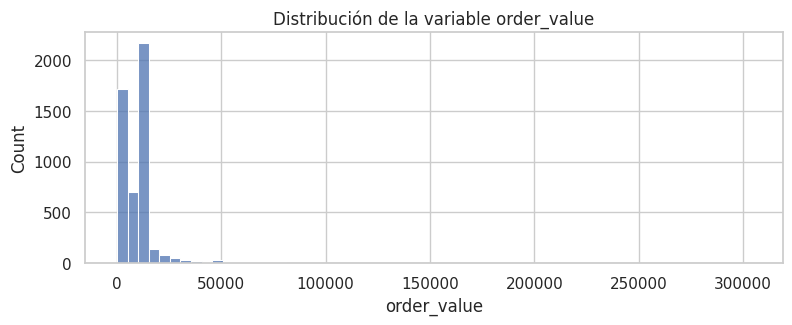

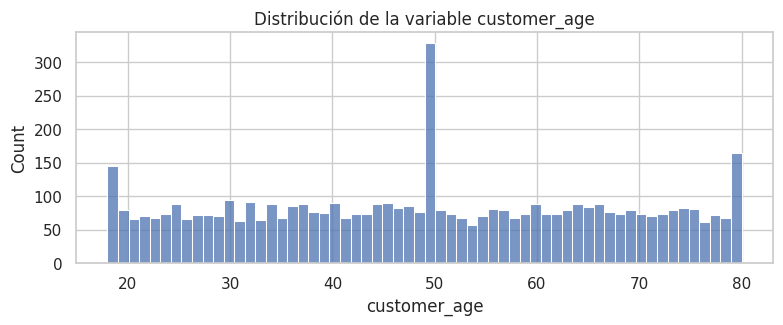

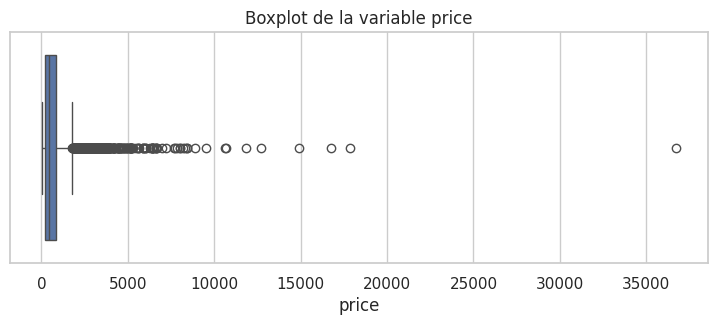

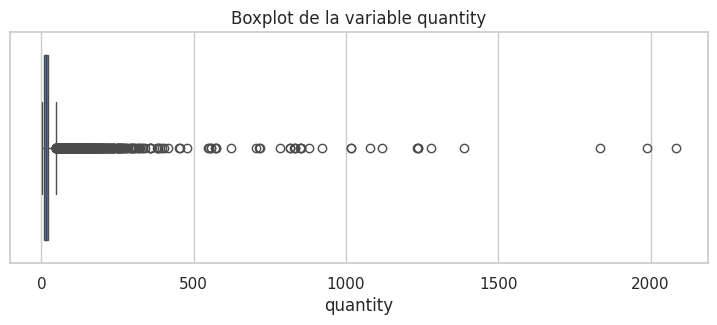

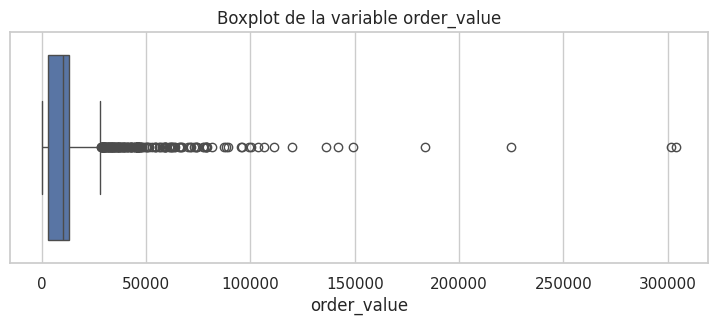

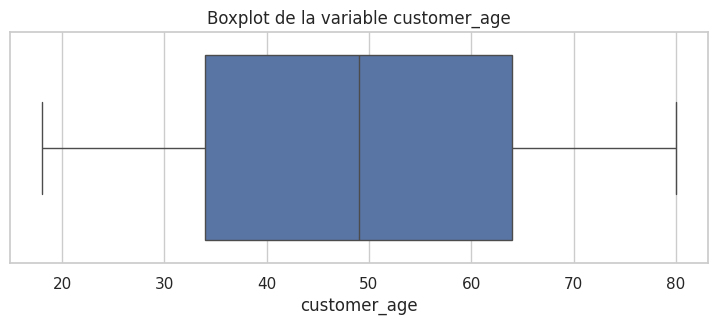

In [ ]:
for col in num_cols:
    plt.figure(figsize=(9, 3))
    sns.histplot(df[col].dropna(), bins=60)
    plt.title(f"Distribución de la variable {col}")
    plt.show()

for col in num_cols:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de la variable {col}")
    plt.show()

## 4. Identificación formal de outliers (IQR y Z-Score)
Un valor fuera de los límites estadísticos **no necesariamente es un error**. Primero se revisa su plausibilidad para el negocio.

**Corrección importante del ejemplo de clase:** dentro del ciclo se filtra `df[col]`, no siempre `df['price']`.

In [ ]:
iqr_rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    iqr_rows.append({"variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                     "limite_inferior": lower, "limite_superior": upper,
                     "cantidad_outliers": len(outliers),
                     "porcentaje_outliers": round(100 * len(outliers) / len(df), 2)})
    print(f"{col}: {len(outliers)} observaciones fuera de límites IQR")
    display(outliers[[col]].head(10))

iqr_summary = pd.DataFrame(iqr_rows)
display(iqr_summary)

price: 446 observaciones fuera de límites IQR


,price
64,2106
67,5181
95,1940
123,1947
138,2437
148,1921
184,1983
185,2069
186,2144
188,1810


quantity: 642 observaciones fuera de límites IQR


,quantity
0,50
3,125
8,833
29,202
34,72
39,61
40,116
41,86
51,184
55,253


order_value: 165 observaciones fuera de límites IQR


,order_value
8,45819
123,31152
155,45998
199,36218
265,28970
293,56712
313,45819
369,77649
375,95640
380,39534


customer_age: 0 observaciones fuera de límites IQR


,customer_age


,variable,Q1,Q3,IQR,limite_inferior,limite_superior,cantidad_outliers,porcentaje_outliers
0,price,218.0,847.25,629.25,-725.875,1791.125,446,8.92
1,quantity,7.0,23.00,16.00,-17.000,47.000,642,12.84
2,order_value,3094.0,13160.50,10066.50,-12005.750,28260.250,165,3.30
3,customer_age,34.0,64.00,30.00,-11.000,109.000,0,0.00


In [ ]:
z_rows = []
for col in num_cols:
    std = df[col].std()
    if pd.notna(std) and std > 0:
        z = (df[col] - df[col].mean()) / std
        count = int((z.abs() > 3).sum())
    else:
        count = 0
    z_rows.append({"variable": col, "outliers_z_mayor_3": count})
display(pd.DataFrame(z_rows))

## 5. Clasificación y tratamiento: Drop, Keep o Cap

- **Drop:** valores imposibles o registros comprobados como errores.
- **Keep:** valores extremos reales, por ejemplo compras legítimas de gran volumen.
- **Cap / winsorización:** limitar extremos plausibles si el objetivo es representar mejor al cliente típico.

**Importante:** no aplicaremos cap automáticamente a todas las columnas. La celda siguiente muestra una **simulación reversible** de cap superior al percentil 99 en variables seleccionadas. Ajusta la lista **solo después de revisar los resultados**. Conservamos las columnas originales.

In [ ]:
# EJEMPLO de tratamiento para explorar su efecto, NO decisión definitiva.
# Modifica esta lista tras justificar cada variable en tu informe.
cols_para_cap = [c for c in ["price", "quantity", "order_value"] if c in num_cols]

df_tratado = df.copy()
for col in cols_para_cap:
    p99 = df[col].quantile(0.99)
    df_tratado[f"{col}_capped"] = np.clip(df[col], None, p99)

print("Variables con cap de demostración:", cols_para_cap)
display(df_tratado[[c for col in cols_para_cap for c in [col, f"{col}_capped"]]].head())

Variables con cap de demostración: ['price', 'quantity', 'order_value']


,price,price_capped,quantity,quantity_capped,order_value,order_value_capped
0,269,269.0,50,50.0,13385,13385.0
1,66,66.0,10,10.0,660,660.0
2,267,267.0,19,19.0,5073,5073.0
3,114,114.0,125,125.0,14290,14290.0
4,729,729.0,16,16.0,11754,11754.0


## 6. Estadísticas posteriores al tratamiento
Comparamos antes y después; limitar extremos puede reducir máximos y medias, pero también ocultar segmentos valiosos. La decisión final debe sustentarse en el objetivo del negocio.

In [ ]:
comparacion = []
for col in cols_para_cap:
    for etiqueta, serie in [("original", df[col]), ("cap_p99_demo", df_tratado[f"{col}_capped"])]:
        comparacion.append({"variable": col, "version": etiqueta,
                            "media": serie.mean(), "mediana": serie.median(),
                            "desv_std": serie.std(), "maximo": serie.max()})
display(pd.DataFrame(comparacion))

,variable,version,media,mediana,desv_std,maximo
0,price,original,756.3874,457.0,1173.265182,36708.00
1,price,cap_p99_demo,725.9984,457.0,877.342942,5148.12
2,quantity,original,32.3598,14.0,93.403826,2083.00
3,quantity,cap_p99_demo,27.9301,14.0,48.505516,331.01
4,order_value,original,10075.5238,10341.0,12406.603152,303824.00
5,order_value,cap_p99_demo,9694.7621,10341.0,8677.328642,56150.67


## 7. Segmentación de volumen
Ejercicio realizado con `np.where()`: cantidades mayores a 22 son **High Volume**.

In [ ]:
if "quantity" in df.columns:
    df["volume_segment"] = np.where(df["quantity"] > 22, "High Volume", "Low Volume")
    print(df["volume_segment"].value_counts(dropna=False))

volume_segment
Low Volume     3739
High Volume    1261
Name: count, dtype: int64


### 7.1 Segmentación avanzada por edad y volumen (`apply`)
La función conserva el manejo de faltantes del ejercicio de TripleTen.

In [ ]:
def classify_volume(row):
    age = row['customer_age']
    qty = row['quantity']

    # 1. Manejo de valores nulos/faltantes
    if pd.isna(age) or pd.isna(qty):
        return "Error en Datos"

    # --- 2. Segmentación de Altas Cantidades ---
    if qty > 22:
        if age > 55:
            return "Sr. High Volume"
        else:
            return "Jr. High Volume"

    # --- 3. Segmentación Bajas Cantidades ---
    elif qty <= 22:
        if age > 55:
            return "Sr. Low Volume"
        else:
            return "Jr. Low Volume"

if {"customer_age", "quantity"}.issubset(df.columns):
    df["volume_age_segment"] = df.apply(classify_volume, axis=1)
    print(df["volume_age_segment"].value_counts())
else:
    print("No están disponibles customer_age y quantity para esta segmentación.")

volume_age_segment
Jr. Low Volume     3004
Sr. High Volume    1197
Sr. Low Volume      735
Jr. High Volume      64
Name: count, dtype: int64


### 7.2 Segmentación por método de pago y volumen
Se basa en el ejercicio con `everpeak_retail.csv`. Si no se carga ese archivo, se usa `everpeak_clean.csv` **solo si contiene ambas columnas**.

In [ ]:
def classify_payment(row):
    card = row['payment_method']
    qty = row['quantity']

    # 1. Manejo de valores nulos/faltantes
    if pd.isna(card) or pd.isna(qty):
        return "Error en Datos"

    # --- 2. Segmentación de Altas Cantidades ---
    if qty > 22:
        if card == "credit_card" or card == "debit_card":
            return "card_high_volume"
        else:
            return "no_card_high_volume"

    # --- 3. Segmentación Bajas Cantidades ---
    elif qty <= 22:
        if card == "credit_card" or card == "debit_card":
            return "card_low_volume"
        else:
            return "no_card_low_volume"

if retail_path.exists():
    df_payment = pd.read_csv(retail_path)
else:
    df_payment = df.copy()

if {"payment_method", "quantity"}.issubset(df_payment.columns):
    df_payment['payment_segment'] = df_payment.apply(classify_payment, axis=1)
    print(df_payment['payment_segment'].value_counts())
else:
    print("Para este ejercicio carga everpeak_retail.csv con payment_method y quantity.")

payment_segment
card_low_volume        2725
no_card_low_volume     1041
card_high_volume        909
no_card_high_volume     333
Name: count, dtype: int64


## 8. Statistical Summary — completar con los resultados reales

**Visión general:** El dataset limpio de EverPeak contiene 5,000 registros y 14 columnas. En la revisión inicial no se identificaron valores nulos ni filas completamente duplicadas.

Las variables numéricas analizadas fueron price, quantity, order_value y customer_age..]

**Distribuciones:** En la variable price, la media (756.39) es superior a la mediana (457), lo que sugiere una distribución sesgada hacia valores altos. En quantity sucede algo similar, ya que la media (32.36) supera la mediana (14), indicando la presencia de compras de mayor volumen que influyen en el promedio.

En order_value, la media (10,075.52) y la mediana (10,341) son relativamente cercanas, aunque se identificaron valores extremos. Por su parte, customer_age presenta una media de 49.12 y una mediana de 49, mostrando una distribución más equilibrada entre ambas medidas.

**Outliers:** Mediante el método del rango intercuartílico (IQR) se identificaron 446 valores atípicos en price (8.92%), 642 en quantity (12.84%) y 165 en order_value (3.30%). En customer_age no se identificaron valores atípicos mediante este método.

Los valores extremos no necesariamente representan errores, ya que pueden corresponder a transacciones legítimas de alto precio o volumen. Por ello, es importante revisar su contexto antes de eliminarlos o modificarlos.

Los resultados específicos del método Z-Score están pendientes de incorporarse tras revisar la salida correspondiente en Colab.

**Decisión por variable:**

| Variable | Evidencia | Decisión: drop / keep / cap | Justificación de negocio |
|---|---|---|---|
| `price` | 446 outliers IQR (8.92%) | Keep provisional | Los precios elevados pueden representar productos legítimos de mayor valor. |
| `quantity` | 642 outliers IQR (12.84%) | Keep provisional | Las compras de alto volumen pueden ser importantes para el negocio. |
| `order_value` | 165 outliers IQR (3.30%) | Keep provisional | Las transacciones elevadas pueden representar clientes de alto valor. |
| `customer_age` | 0 outliers IQR | Keep | No se identificaron valores atípicos mediante IQR. |


**Impacto del tratamiento:** Se realizó una simulación de winsorización al percentil 99 en las variables price, quantity y order_value, conservando las columnas originales para comparar los resultados.

Este procedimiento permite observar cómo cambian la media, la mediana, la desviación estándar y los valores máximos cuando se limitan los extremos. Sin embargo, el tratamiento no se considera definitivo, ya que primero debe evaluarse si las observaciones representan errores o transacciones válidas.

La comparación numérica del antes y después se encuentra en la sección 6 del notebook.

## 9. Conclusión ejecutiva
El análisis exploratorio de EverPeak permitió evaluar la calidad de los datos e identificar patrones en las transacciones que pueden apoyar la toma de decisiones comerciales.

Principales hallazgos:

Calidad de los datos: El dataset limpio contiene 5,000 registros y 14 columnas, sin valores nulos ni filas completamente duplicadas. Esto proporciona una base adecuada para el análisis exploratorio.

Comportamiento de las compras: Las variables price y quantity presentan medias superiores a sus medianas, lo que sugiere que las transacciones con precios o cantidades elevadas influyen en los promedios. Por ello, es importante analizar tanto las medidas de tendencia central como las distribuciones completas.

Valores atípicos: Mediante IQR se identificaron 446 observaciones atípicas en price, 642 en quantity y 165 en order_value. Estos valores no deben eliminarse automáticamente, ya que podrían representar operaciones comerciales legítimas.

Segmentación por volumen: El 74.78% de las transacciones corresponde a Low Volume (3,739 registros), mientras que el 25.22% pertenece a High Volume (1,261 registros). Esta diferencia permite distinguir dos grupos de comportamiento de compra que podrían requerir estrategias comerciales distintas.

Segmentación por edad y volumen: El segmento Jr. Low Volume concentra 3,004 transacciones, siendo el grupo más frecuente según los criterios establecidos en los ejercicios. Este resultado permite identificar un segmento relevante para futuros análisis de comportamiento del cliente.

Recomendaciones de negocio:

Se recomienda profundizar en el análisis de las compras de alto volumen para identificar su contribución a las ventas y evaluar posibles estrategias de fidelización.

Asimismo, es conveniente utilizar los segmentos identificados para comparar hábitos de compra y métodos de pago, sin asumir que los grupos representan necesariamente perfiles definitivos de clientes.

Finalmente, antes de eliminar o limitar valores atípicos, EverPeak debería revisar su validez comercial para evitar la pérdida de información relevante.

**Límite del análisis:**

El análisis se realizó a partir de un conjunto de datos de 5,000 transacciones, por lo que los resultados representan únicamente el comportamiento observado en la información disponible.

Los criterios de segmentación por volumen de compra y edad se establecieron mediante umbrales definidos previamente. Aunque permiten identificar patrones iniciales, será necesario evaluar su capacidad para diferenciar comportamientos comerciales y determinar si requieren ajustes.

Asimismo, los valores atípicos identificados mediante métodos estadísticos no deben interpretarse automáticamente como errores. Su tratamiento requiere validar el contexto de las transacciones y evaluar el impacto de cualquier modificación sobre los indicadores de negocio.

Por lo tanto, los hallazgos constituyen una base para profundizar en el análisis y desarrollar recomendaciones comerciales respaldadas por evidencia adicional.

## 10. Reproducibilidad y control de versiones

El proyecto EverPeak Retail Analysis se desarrolló en Python utilizando pandas, NumPy, Matplotlib y Seaborn. El notebook documenta el proceso de exploración, evaluación de calidad de datos, análisis estadístico, identificación de valores atípicos y segmentación de transacciones.

**Reproducibilidad del análisis:**

1. Abrir el notebook en Google Colab o Jupyter Notebook.
2. Cargar los archivos `everpeak_clean.csv` y `everpeak_retail.csv`.
3. Ejecutar las celdas en orden para reproducir los resultados y las visualizaciones.
4. Revisar las conclusiones cuando se actualicen los datos.

**Control de versiones:**

El proyecto está preparado para mantenerse en GitHub, donde los cambios del código, los análisis y la documentación podrán registrarse mediante commits descriptivos.

**Consideraciones sobre los datos:**

Los archivos utilizados deben manejarse conforme a sus condiciones de uso. El código y la metodología pueden compartirse sin necesidad de publicar los datasets originales.